<a href="https://colab.research.google.com/github/thomas-andromeda/Belajar-Filament/blob/main/Praktikum_02_Klasifikasi_Gambar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Praktikum D1 – Memulai Klasifikasi Gambar dengan Dataset Sederhana**

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


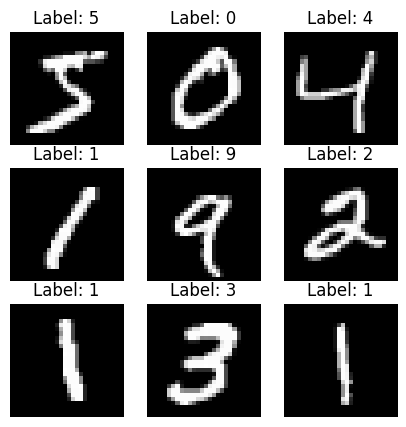

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
# Load data
(x_train, y_train), (x_test, y_test) = mnist.load_data()
# Tampilkan contoh
plt.figure(figsize=(5,5))
for i in range(9):
 plt.subplot(3,3,i+1)
 plt.imshow(x_train[i], cmap='gray')
 plt.title(f"Label: {y_train[i]}")
 plt.axis('off')
plt.show()

**Tugas kecil:** Cobalah ganti range(9) dengan range(25) untuk menampilkan lebih banyak contoh. Apa yang Anda perhatikan dari bentuk tulisan tangan manusia?

*   Variasi Gaya Penulisan (Variability)
*   Ketebalan dan Kemiringan (Thickness & Slant)
*   Ambuitas / Kemiripan Bentuk (Ambiguity)

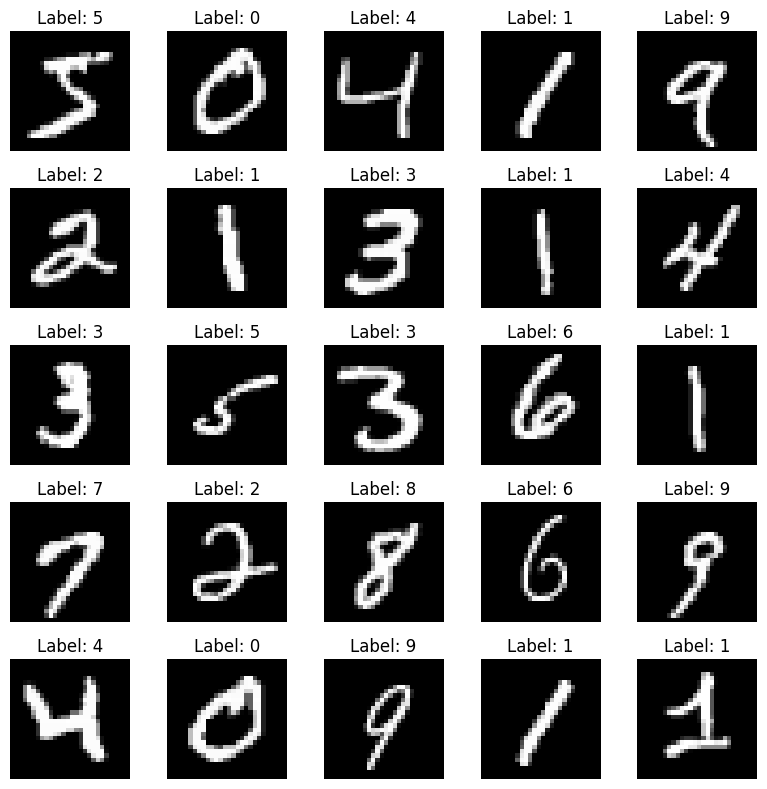

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist

# Load data
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Tampilkan 25 contoh
plt.figure(figsize=(8, 8))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

# **Praktikum D2 – Klasifikasi Gambar dengan Model Machine Learning Tradisional**

In [ ]:
from sklearn import svm
from sklearn.metrics import accuracy_score
# Flatten
x_train_flat = x_train.reshape(len(x_train), -1) / 255.0
x_test_flat = x_test.reshape(len(x_test), -1) / 255.0
# SVM
clf = svm.SVC(kernel='linear', gamma='scale')
clf.fit(x_train_flat[:5000], y_train[:5000]) # gunakan subset karena SVM berat
y_pred = clf.predict(x_test_flat)
print("Akurasi:", accuracy_score(y_test, y_pred))

Akurasi: 0.9101


**Tugas kecil:** Ubah kernel dari linear menjadi rbf. Bagaimana pengaruhnya terhadap akurasi?

Kernel RBF meningkatkan akurasi karena mampu membentuk batas keputusan non-linear (melengkung dan fleksibel) yang jauh lebih efektif menangkap pola serta variasi kompleks tulisan tangan dibanding kernel linear yang hanya bisa memisahkan data dengan garis/bidang lurus.

In [5]:
from sklearn import svm
from sklearn.metrics import accuracy_score

# Flatten & Normalisasi
x_train_flat = x_train.reshape(len(x_train), -1) / 255.0
x_test_flat = x_test.reshape(len(x_test), -1) / 255.0

# SVM dengan kernel RBF
clf = svm.SVC(kernel='rbf', gamma='scale')
clf.fit(x_train_flat[:5000], y_train[:5000]) # subset 5000 sampel
y_pred = clf.predict(x_test_flat)

print("Akurasi:", accuracy_score(y_test, y_pred))

Akurasi: 0.9513


# **Praktikum D3 – Membangun CNN Sederhana**

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 12s 5ms/step - accuracy: 0.9441 - loss: 0.1882 - val_accuracy: 0.9805 - val_loss: 0.0720
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9802 - loss: 0.0646 - val_accuracy: 0.9837 - val_loss: 0.0571
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9862 - loss: 0.0442 - val_accuracy: 0.9852 - val_loss: 0.0558
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9901 - loss: 0.0320 - val_accuracy: 0.9857 - val_loss: 0.0511
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9925 - loss: 0.0233 - val_accuracy: 0.9877 - val_loss: 0.0512


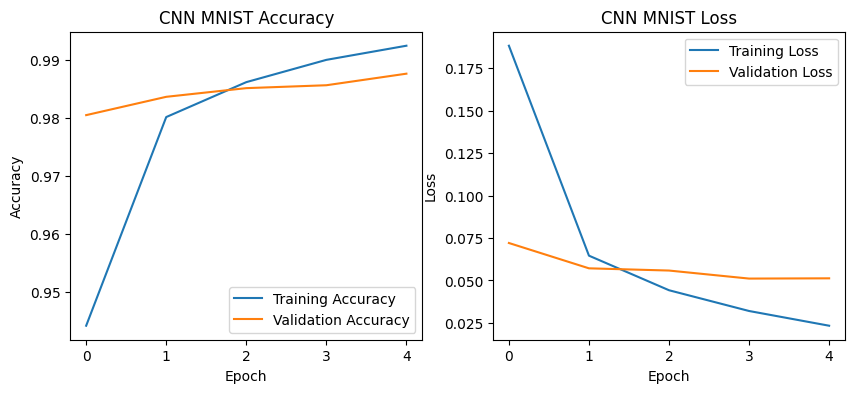

In [25]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist

# 1. Load dataset MNIST
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# 2. Reshape ke (28, 28, 1) dan normalisasi
x_train_cnn = x_train.reshape(-1, 28, 28, 1) / 255.0
x_test_cnn = x_test.reshape(-1, 28, 28, 1) / 255.0

# 3. Model CNN D3 (Khusus MNIST)
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax'),
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

# 4. Latih model
history = model.fit(x_train_cnn, y_train, epochs=5, validation_split=0.1)

# 5. Plot history
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('CNN MNIST Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('CNN MNIST Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

**Tugas kecil:** Tambahkan satu lapisan Conv2D lagi sebelum Flatten. Apakah akurasinya meningkat?

**Ekstraksi Fitur Abstrak**: Lapisan tambahan mampu mengekstraksi fitur visual yang lebih kompleks dan detail (seperti bentuk atau bagian spesifik objek), tidak sekadar garis dan tepi dasar.

**Representasi Data Lebih Efisien**: Memperkecil dan memperdalam peta fitur secara bertahap sehingga informasi yang masuk ke Dense layer lebih terfokus, sekaligus menekan risiko overfitting.

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 13s 5ms/step - accuracy: 0.9535 - loss: 0.1515 - val_accuracy: 0.9852 - val_loss: 0.0487
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9848 - loss: 0.0493 - val_accuracy: 0.9872 - val_loss: 0.0478
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9889 - loss: 0.0343 - val_accuracy: 0.9878 - val_loss: 0.0435
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9920 - loss: 0.0252 - val_accuracy: 0.9902 - val_loss: 0.0352
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9941 - loss: 0.0185 - val_accuracy: 0.9872 - val_loss: 0.0428


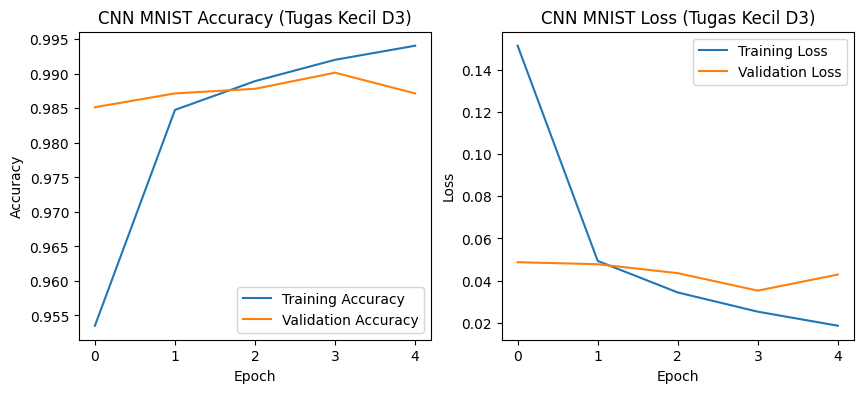

In [27]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist

# 1. Load dataset MNIST
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# 2. Reshape & Normalisasi
x_train_cnn = x_train.reshape(-1, 28, 28, 1) / 255.0
x_test_cnn = x_test.reshape(-1, 28, 28, 1) / 255.0

# 3. Model CNN D3 + Tugas Kecil (Menambahkan Conv2D ke-2 sebelum Flatten)
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),
    # --- Tambahan Conv2D untuk Tugas Kecil D3 ---
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    # --------------------------------------------
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax'),
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

history = model.fit(x_train_cnn, y_train, epochs=5, validation_split=0.1)

# Plot history
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('CNN MNIST Accuracy (Tugas Kecil D3)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('CNN MNIST Loss (Tugas Kecil D3)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# **Praktikum D4 – Eksperimen dengan Dataset Lebih Kompleks (CIFAR-10)**

Epoch 1/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.4366 - loss: 1.5469 - val_accuracy: 0.5356 - val_loss: 1.2942
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.5771 - loss: 1.1908 - val_accuracy: 0.5852 - val_loss: 1.1696
Epoch 3/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6344 - loss: 1.0349 - val_accuracy: 0.6484 - val_loss: 0.9974
Epoch 4/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6727 - loss: 0.9317 - val_accuracy: 0.6594 - val_loss: 0.9713
Epoch 5/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7005 - loss: 0.8572 - val_accuracy: 0.6722 - val_loss: 0.9292
Epoch 6/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7210 - loss: 0.7989 - val_accuracy: 0.6876 - val_loss: 0.8943
Epoch 7/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7379 - loss: 0.7458 - val_accuracy: 0.6892 - val_loss: 0.9244
Epoch 8/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7557 - loss: 0.6959 -

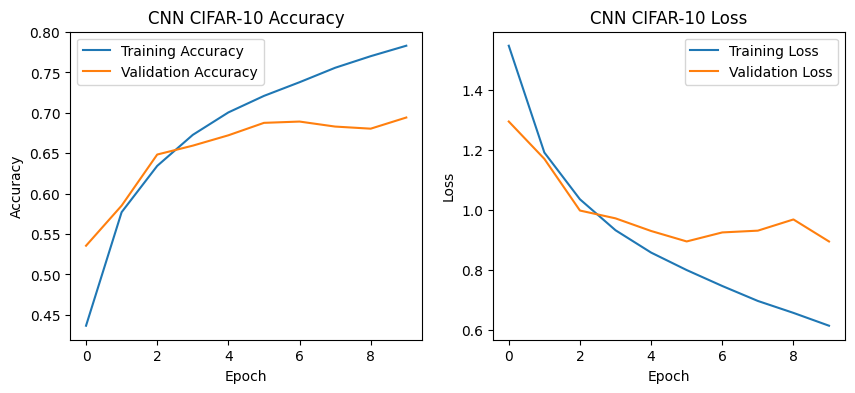

In [12]:
!pip install -q datasets

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from datasets import load_dataset

# Load dataset CIFAR-10 dari Hugging Face Hub
ds = load_dataset("uoft-cs/cifar10")

# Menyesuaikan nama kolom gambar secara otomatis ('img' atau 'image')
img_col = "img" if "img" in ds["train"].column_names else "image"

x_train = np.stack([np.array(i) for i in ds["train"][img_col]]) / 255.0
y_train = np.array(ds["train"]["label"]).reshape(-1, 1)
x_test = np.stack([np.array(i) for i in ds["test"][img_col]]) / 255.0
y_test = np.array(ds["test"]["label"]).reshape(-1, 1)

# Arsitektur Model CNN dengan 3 Lapisan Conv2D
model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    # Blok Konvolusi 1: Deteksi fitur dasar (garis, sudut, warna)
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Blok Konvolusi 2: Deteksi tekstur dan pola menengah
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Blok Konvolusi 3: Deteksi objek spesifik dan fitur kompleks
    layers.Conv2D(64, (3, 3), activation='relu'),

    # Lapisan Klasifikasi
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

# Kompilasi Model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Pelatihan Model
history = model.fit(x_train, y_train, epochs=10, validation_split=0.1)

# Evaluasi pada data tes
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"\nAkurasi Data Tes: {test_acc * 100:.2f}%")

# Visualisasi Grafik Akurasi dan Loss
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('CNN CIFAR-10 Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('CNN CIFAR-10 Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

**Tugas kecil:** Coba tambahkan Dropout(0.5) sebelum lapisan Dense terakhir. Apa pengaruhnya pada overfitting?

Mencegah Koadaptasi Neuron: Mematikan 50% neuron secara acak memaksa jaringan belajar fitur secara mandiri tanpa bergantung pada neuron tertentu, sehingga kemampuan generalisasi model pada data baru meningkat.

Mengecilkan Celah Training dan Validation: Menahan model agar tidak menghafal noise pada data latih, sehingga kurva validation loss tetap stabil dan perbedaan (gap) performa antara data training dan validation menjadi jauh lebih kecil.

Epoch 1/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.3549 - loss: 1.7426 - val_accuracy: 0.4948 - val_loss: 1.4088
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.4922 - loss: 1.4055 - val_accuracy: 0.5746 - val_loss: 1.1783
Epoch 3/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.5548 - loss: 1.2550 - val_accuracy: 0.6076 - val_loss: 1.0906
Epoch 4/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.5914 - loss: 1.1538 - val_accuracy: 0.6184 - val_loss: 1.0731
Epoch 5/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6188 - loss: 1.0829 - val_accuracy: 0.6580 - val_loss: 0.9699
Epoch 6/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6410 - loss: 1.0242 - val_accuracy: 0.6726 - val_loss: 0.9347
Epoch 7/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6602 - loss: 0.9740 - val_accuracy: 0.6734 - val_loss: 0.9282
Epoch 8/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6755 - loss: 0.9294 -

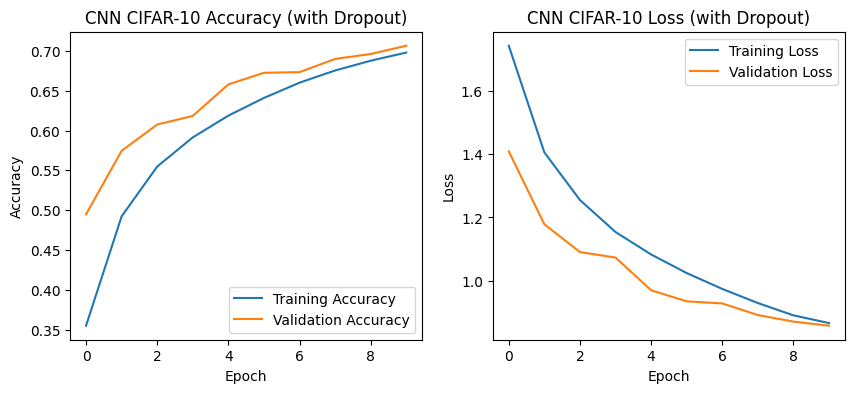

In [13]:
!pip install -q datasets

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from datasets import load_dataset

# Load dataset CIFAR-10 dari Hugging Face Hub
ds = load_dataset("uoft-cs/cifar10")

# Menyesuaikan nama kolom gambar secara otomatis ('img' atau 'image')
img_col = "img" if "img" in ds["train"].column_names else "image"

x_train = np.stack([np.array(i) for i in ds["train"][img_col]]) / 255.0
y_train = np.array(ds["train"]["label"]).reshape(-1, 1)
x_test = np.stack([np.array(i) for i in ds["test"][img_col]]) / 255.0
y_test = np.array(ds["test"]["label"]).reshape(-1, 1)

# Arsitektur Model CNN dengan tambahan Dropout(0.5)
model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    # Blok Konvolusi 1
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Blok Konvolusi 2
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Blok Konvolusi 3
    layers.Conv2D(64, (3, 3), activation='relu'),

    # Lapisan Klasifikasi
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.5),  # Ditambahkan sebelum lapisan Dense terakhir
    layers.Dense(10, activation='softmax')
])

# Kompilasi Model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Pelatihan Model
history = model.fit(x_train, y_train, epochs=10, validation_split=0.1)

# Evaluasi pada data tes
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"\nAkurasi Data Tes: {test_acc * 100:.2f}%")

# Visualisasi Grafik Akurasi dan Loss
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('CNN CIFAR-10 Accuracy (with Dropout)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('CNN CIFAR-10 Loss (with Dropout)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

# **Praktikum D5 – Transfer Learning dengan Model Pra-Latih**

Epoch 1/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 25s 14ms/step - accuracy: 0.5217 - loss: 1.3781 - val_accuracy: 0.5732 - val_loss: 1.2392
Epoch 2/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - accuracy: 0.5824 - loss: 1.1980 - val_accuracy: 0.5952 - val_loss: 1.1732
Epoch 3/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 19s 8ms/step - accuracy: 0.6018 - loss: 1.1413 - val_accuracy: 0.5984 - val_loss: 1.1487
Epoch 4/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.6162 - loss: 1.0975 - val_accuracy: 0.5990 - val_loss: 1.1460
Epoch 5/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - accuracy: 0.6265 - loss: 1.0660 - val_accuracy: 0.6150 - val_loss: 1.1191


Text(0.5, 0, 'Epoch')

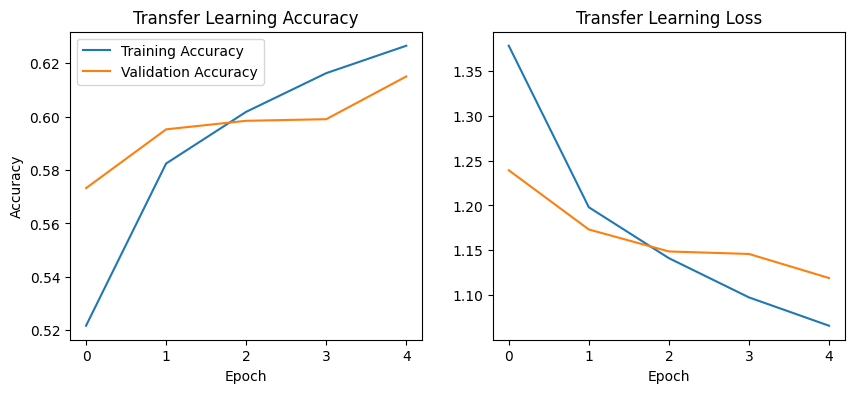

In [14]:
from tensorflow.keras.applications import VGG16

base_model = VGG16(weights='imagenet', include_top=False, input_shape=(32, 32, 3))
base_model.trainable = False

model = models.Sequential([
    base_model,
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(x_train, y_train, epochs=5, validation_split=0.1)

# ===== Plot history =====
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Transfer Learning Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Transfer Learning Loss')
plt.xlabel('Epoch')

**Tugas kecil:** Coba aktifkan 1–2 lapisan terakhir dari base_model (fine-tuning). Bagaimana akurasinya berubah?

Meningkatkan Akurasi Maksimal: Memungkinkan model menyesuaikan fitur tingkat tinggi dengan karakteristik spesifik dataset baru, sehingga akurasi pelatihan dan validasi umumnya meningkat dibanding feature extraction biasa.

Risiko Overfitting: Jika learning rate terlalu besar atau dataset kecil, akurasi latih bisa sangat tinggi tetapi akurasi validasi justru turun.

Ketergantungan pada Learning Rate: Akurasi hanya akan meningkat stabil jika menggunakan learning rate yang sangat kecil (misal $10^{-5}$) agar tidak merusak bobot yang sudah terlatih baik (catastrophic forgetting).

Epoch 1/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 20s 10ms/step - accuracy: 0.5196 - loss: 1.3796 - val_accuracy: 0.5680 - val_loss: 1.2435
Epoch 2/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 14s 10ms/step - accuracy: 0.5801 - loss: 1.1986 - val_accuracy: 0.5842 - val_loss: 1.1848
Epoch 3/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.6027 - loss: 1.1421 - val_accuracy: 0.5914 - val_loss: 1.1582
Epoch 4/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.6142 - loss: 1.1009 - val_accuracy: 0.5938 - val_loss: 1.1671
Epoch 5/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.6264 - loss: 1.0681 - val_accuracy: 0.6032 - val_loss: 1.1275
Epoch 1/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 21s 12ms/step - accuracy: 0.6602 - loss: 0.9714 - val_accuracy: 0.6338 - val_loss: 1.0305
Epoch 2/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - accuracy: 0.6894 - loss: 0.8940 - val_accuracy: 0.6492 - val_loss: 1.0004
Epoch 3/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.7075 - loss: 0.841

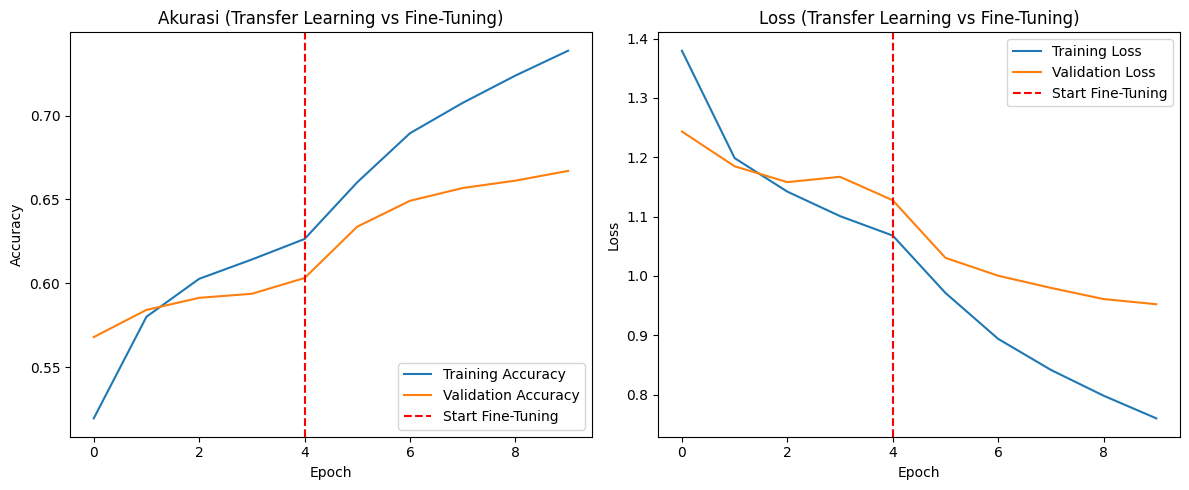

In [17]:
import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras import models, layers
import matplotlib.pyplot as plt

base_model = VGG16(weights='imagenet', include_top=False, input_shape=(32, 32, 3))
base_model.trainable = False

model = models.Sequential([
    base_model,
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(x_train, y_train, epochs=5, validation_split=0.1)

base_model.trainable = True

for layer in base_model.layers[:-2]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_fine = model.fit(x_train, y_train, epochs=5, validation_split=0.1)

acc = history.history['accuracy'] + history_fine.history['accuracy']
val_acc = history.history['val_accuracy'] + history_fine.history['val_accuracy']
loss = history.history['loss'] + history_fine.history['loss']
val_loss = history.history['val_loss'] + history_fine.history['val_loss']

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.axvline(x=len(history.history['accuracy'])-1, color='red', linestyle='--', label='Start Fine-Tuning')
plt.title('Akurasi (Transfer Learning vs Fine-Tuning)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')

plt.subplot(1, 2, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.axvline(x=len(history.history['loss'])-1, color='red', linestyle='--', label='Start Fine-Tuning')
plt.title('Loss (Transfer Learning vs Fine-Tuning)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

# **Praktikum D6 – Evaluasi dengan Confusion Matrix dan Metrik Lain**

313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step
              precision    recall  f1-score   support

           0       0.67      0.71      0.69      1000
           1       0.57      0.76      0.65      1000
           2       0.54      0.49      0.51      1000
           3       0.51      0.34      0.41      1000
           4       0.56      0.53      0.54      1000
           5       0.54      0.57      0.55      1000
           6       0.64      0.65      0.65      1000
           7       0.60      0.71      0.65      1000
           8       0.76      0.68      0.72      1000
           9       0.61      0.59      0.60      1000

    accuracy                           0.60     10000
   macro avg       0.60      0.60      0.60     10000
weighted avg       0.60      0.60      0.60     10000



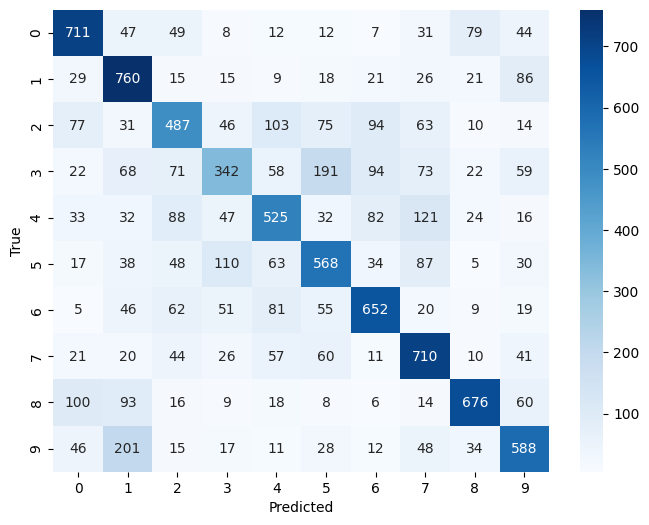

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
y_pred = model.predict(x_test).argmax(axis=1)
print(classification_report(y_test, y_pred))
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

**Tugas kecil:** Dari confusion matrix, identifikasi kelas apa yang paling sering salah diklasifikasikan. Menurut Anda, mengapa hal itu bisa terjadi?

Secara umum dalam machine learning / deep learning, sebuah kelas sering salah diklasifikasikan karena beberapa faktor utama:


*   Kemiripan Fitur (Feature Overlap)
*   Ketidakseimbangan Data (Class Imbalance)
*   Kualitas Data dan Noise:
*   Kurangnya Representasi Fitur (Underfitting pada kelas tertentu)


# **Mencoba klasifikasi tulisan angka:**

(Pilihan A) Prediksi dengan CNN dari D3

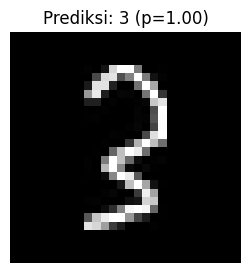

Rekap Prediksi (CNN):
- 3number (1).png -> 3 (p=1.000)


In [26]:
import matplotlib.pyplot as plt

results = []
for fname in uploaded.keys():
  img_pil = Image.open(fname)
  disp, x = preprocess_to_mnist_28x28(img_pil)
  x_batch = np.expand_dims(x, axis=0)

  probs = model.predict(x_batch, verbose=0)[0]
  pred = int(np.argmax(probs))
  conf = float(np.max(probs))
  results.append((fname, pred, conf))

  plt.figure(figsize=(3, 3))
  plt.imshow(disp, cmap='gray')
  plt.title(f'Prediksi: {pred} (p={conf:.2f})')
  plt.axis('off')
  plt.show()

print('Rekap Prediksi (CNN):')
for r in results:
  print(f'- {r[0]} -> {r[1]} (p={r[2]:.3f})')